In [2]:
pwd

'C:\\Users\\Hp'

In [3]:
import os
os.chdir(r'G:\IoT_IDS_Research')

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import time

In [5]:
pwd

'G:\\IoT_IDS_Research'

In [6]:
# IoT IDS Preprocessing Pipeline for CIC IoT Attack Dataset 2023
# Author: Prepared for IoT Security IDS research
# Purpose: Clean, optimize, sample, and prepare merged CICIoT2023 CSV files for ML experiments.

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

# =========================
# 1. CONFIGURATION
# =========================

RAW_DIR = Path("data/raw")              # Put your 63 merged CSV files here
PROCESSED_DIR = Path("data/processed")  # Cleaned files will be saved here
OUTPUT_DIR = Path("outputs")            # Reports/encoders/scalers

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COL = "Label"
CHUNK_SIZE = 100_000

# For your laptop, start with a small sample.
# Later you can increase this to 500000 or 1000000.
FINAL_SAMPLE_SIZE = 200_000

# Balanced binary sampling settings.
# For FINAL_SAMPLE_SIZE = 200_000, the script will try to create:
#   100,000 BENIGN rows + 100,000 ATTACK rows.
# If one class has fewer rows in the cleaned dataset, the script will use the
# maximum possible balanced size without duplicating rows.
BALANCED_BINARY_SAMPLE = True
ALLOW_REPLACEMENT_IF_MINORITY_SHORT = False

RANDOM_STATE = 42

In [7]:
# =========================
# 2. ATTACK CATEGORY MAPPING
# =========================

def map_attack_category(label: str) -> str:
    """
    Map 34 fine-grained CICIoT2023 labels into broader attack categories.
    This is useful for multiclass category-level IDS.
    """
    label = str(label).upper().strip()

    if label == "BENIGN":
        return "BENIGN"
    elif label.startswith("DDOS"):
        return "DDOS"
    elif label.startswith("DOS"):
        return "DOS"
    elif label.startswith("MIRAI"):
        return "MIRAI"
    elif label.startswith("RECON"):
        return "RECON"
    elif "SPOOFING" in label or "MITM" in label:
        return "SPOOFING"
    elif label in ["SQLINJECTION", "COMMANDINJECTION", "XSS", "BROWSERHIJACKING", "UPLOADING_ATTACK", "BACKDOOR_MALWARE"]:
        return "WEB_OR_MALWARE"
    elif label == "DICTIONARYBRUTEFORCE":
        return "BRUTEFORCE"
    elif label == "VULNERABILITYSCAN":
        return "VULNERABILITY_SCAN"
    else:
        return "OTHER"

In [8]:
# =========================
# 3. MEMORY OPTIMIZATION
# =========================

def optimize_dtypes(df: pd.DataFrame) -> pd.DataFrame:
    """
    Reduce RAM usage by converting float64 to float32 and int64 to smaller integer types.
    """
    for col in df.select_dtypes(include=["float64"]).columns:
        df[col] = df[col].astype("float32")

    for col in df.select_dtypes(include=["int64"]).columns:
        df[col] = pd.to_numeric(df[col], downcast="integer")

    return df

In [9]:
# =========================
# 4. CLEAN ONE CHUNK
# =========================

def clean_chunk(chunk: pd.DataFrame) -> pd.DataFrame:
    """
    Clean one chunk of the dataset.
    """
    # Remove spaces from column names for easier coding
    chunk.columns = [c.strip().replace(" ", "_") for c in chunk.columns]

    target_col = TARGET_COL
    if TARGET_COL not in chunk.columns and "Label" in chunk.columns:
        target_col = "Label"

    # Replace infinity with NaN
    chunk = chunk.replace([np.inf, -np.inf], np.nan)

    # Fill numeric missing values with median of the chunk
    numeric_cols = chunk.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        if chunk[col].isna().any():
            chunk[col] = chunk[col].fillna(chunk[col].median())

    # Drop rows without label
    if target_col in chunk.columns:
        chunk[target_col] = chunk[target_col].astype(str).str.upper().str.strip()
        chunk = chunk[chunk[target_col] != ""]
        chunk = chunk.dropna(subset=[target_col])

        # Create binary and category labels
        chunk["Binary_Label"] = chunk[target_col].apply(lambda x: 0 if x == "BENIGN" else 1)
        chunk["Attack_Category"] = chunk[target_col].apply(map_attack_category)

    # Remove duplicate rows inside the chunk
    chunk = chunk.drop_duplicates()

    # Optimize RAM
    chunk = optimize_dtypes(chunk)

    return chunk

In [10]:
# =========================
# 5. PREPROCESS ALL CSV FILES
# =========================

def preprocess_all_files():
    csv_files = sorted(RAW_DIR.glob("*.csv"))

    if not csv_files:
        raise FileNotFoundError(f"No CSV files found in {RAW_DIR.resolve()}")

    print(f"Found {len(csv_files)} CSV files.")

    processed_files = []

    for file_index, csv_file in enumerate(csv_files, start=1):
        print(f"\nProcessing file {file_index}/{len(csv_files)}: {csv_file.name}")

        output_file = PROCESSED_DIR / f"cleaned_{csv_file.stem}.parquet"

        cleaned_chunks = []
        total_rows = 0

        for chunk in pd.read_csv(csv_file, chunksize=CHUNK_SIZE):
            total_rows += len(chunk)
            cleaned = clean_chunk(chunk)
            cleaned_chunks.append(cleaned)

        file_df = pd.concat(cleaned_chunks, ignore_index=True)
        file_df = file_df.drop_duplicates()

        file_df.to_parquet(output_file, index=False)
        processed_files.append(output_file)

        print(f"Original rows read: {total_rows}")
        print(f"Cleaned rows saved: {len(file_df)}")
        print(f"Saved: {output_file}")

    return processed_files

In [11]:
# =========================
# 6. CREATE FINAL BALANCED SAMPLE
# =========================

def _allocate_samples(counts, target):
    """
    Allocate a target number of samples across files proportionally to the
    available class counts in each file.

    This avoids selecting too many rows from a file that has very few BENIGN
    or ATTACK samples.
    """
    counts = np.array(counts, dtype=np.int64)
    total_available = int(counts.sum())

    if total_available == 0 or target <= 0:
        return [0] * len(counts)

    target = min(int(target), total_available)

    raw_alloc = (counts / total_available) * target
    alloc = np.floor(raw_alloc).astype(np.int64)

    # Never allocate more than available in any file.
    alloc = np.minimum(alloc, counts)

    # Distribute the remaining samples to files that still have capacity.
    remaining = target - int(alloc.sum())
    fractional_order = np.argsort(-(raw_alloc - np.floor(raw_alloc)))

    while remaining > 0:
        changed = False
        for idx in fractional_order:
            if remaining == 0:
                break
            if alloc[idx] < counts[idx]:
                alloc[idx] += 1
                remaining -= 1
                changed = True
        if not changed:
            break

    return alloc.tolist()


def create_final_sample(processed_files):
    """
    Create one balanced binary working sample from all cleaned parquet files.

    This is better than ordinary random sampling for IDS research because the
    raw CICIoT2023 distribution is highly imbalanced. The default setting tries
    to create 50% BENIGN and 50% ATTACK samples.
    """
    print("\nCreating final balanced research sample...")

    if not BALANCED_BINARY_SAMPLE:
        print("BALANCED_BINARY_SAMPLE=False, using ordinary random sampling.")
        sample_parts = []
        per_file_sample = max(1000, FINAL_SAMPLE_SIZE // len(processed_files))

        for file in processed_files:
            df = pd.read_parquet(file)
            if len(df) > per_file_sample:
                df_sample = df.sample(n=per_file_sample, random_state=RANDOM_STATE)
            else:
                df_sample = df
            sample_parts.append(df_sample)

        sample_df = pd.concat(sample_parts, ignore_index=True)
        if len(sample_df) > FINAL_SAMPLE_SIZE:
            sample_df = sample_df.sample(n=FINAL_SAMPLE_SIZE, random_state=RANDOM_STATE)

    else:
        # First pass: count class availability in every cleaned file.
        file_stats = []
        total_benign = 0
        total_attack = 0

        for file in processed_files:
            df = pd.read_parquet(file, columns=["Binary_Label"])
            benign_count = int((df["Binary_Label"] == 0).sum())
            attack_count = int((df["Binary_Label"] == 1).sum())
            file_stats.append({
                "file": file,
                "benign": benign_count,
                "attack": attack_count
            })
            total_benign += benign_count
            total_attack += attack_count

        desired_per_class = FINAL_SAMPLE_SIZE // 2

        if ALLOW_REPLACEMENT_IF_MINORITY_SHORT:
            benign_target = desired_per_class
            attack_target = desired_per_class
        else:
            # Without replacement, a truly balanced sample cannot exceed the
            # available minority class size.
            per_class_possible = min(desired_per_class, total_benign, total_attack)
            benign_target = per_class_possible
            attack_target = per_class_possible

            if per_class_possible < desired_per_class:
                print("WARNING: Not enough rows in one class for the requested balanced sample.")
                print(f"Requested per class: {desired_per_class}")
                print(f"Available BENIGN   : {total_benign}")
                print(f"Available ATTACK   : {total_attack}")
                print(f"Using per class    : {per_class_possible}")

        print("\nAvailable cleaned rows:")
        print(f"BENIGN: {total_benign}")
        print(f"ATTACK: {total_attack}")
        print("\nSampling target:")
        print(f"BENIGN: {benign_target}")
        print(f"ATTACK: {attack_target}")

        benign_alloc = _allocate_samples(
            [s["benign"] for s in file_stats],
            benign_target
        )
        attack_alloc = _allocate_samples(
            [s["attack"] for s in file_stats],
            attack_target
        )

        sample_parts = []

        for idx, stat in enumerate(file_stats):
            file = stat["file"]
            n_benign = benign_alloc[idx]
            n_attack = attack_alloc[idx]

            if n_benign == 0 and n_attack == 0:
                continue

            df = pd.read_parquet(file)
            parts = []

            benign_df = df[df["Binary_Label"] == 0]
            attack_df = df[df["Binary_Label"] == 1]

            if n_benign > 0:
                replace_b = ALLOW_REPLACEMENT_IF_MINORITY_SHORT and len(benign_df) < n_benign
                parts.append(benign_df.sample(
                    n=n_benign,
                    replace=replace_b,
                    random_state=RANDOM_STATE + idx
                ))

            if n_attack > 0:
                replace_a = ALLOW_REPLACEMENT_IF_MINORITY_SHORT and len(attack_df) < n_attack
                parts.append(attack_df.sample(
                    n=n_attack,
                    replace=replace_a,
                    random_state=RANDOM_STATE + idx
                ))

            file_sample = pd.concat(parts, ignore_index=True)
            sample_parts.append(file_sample)

            print(
                f"Sampled from {file.name}: "
                f"BENIGN={n_benign}, ATTACK={n_attack}"
            )

        sample_df = pd.concat(sample_parts, ignore_index=True)

    # Shuffle final sample.
    sample_df = sample_df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

    output_sample = PROCESSED_DIR / f"balanced_final_sample_{len(sample_df)}.csv"
    compatibility_sample = PROCESSED_DIR / f"final_sample_{FINAL_SAMPLE_SIZE}.csv"

    sample_df.to_csv(output_sample, index=False)
    sample_df.to_csv(compatibility_sample, index=False)

    print(f"\nFinal sample shape: {sample_df.shape}")
    print("Binary label distribution:")
    print(sample_df["Binary_Label"].value_counts().sort_index())
    print(f"Saved balanced sample: {output_sample}")
    print(f"Saved compatibility copy: {compatibility_sample}")

    return sample_df, output_sample

In [12]:
# =========================
# 7. CREATE TRAIN-TEST DATA
# =========================

def create_train_test(sample_df: pd.DataFrame):
    """
    Prepare X_train, X_test, y_train, y_test for Binary IDS.
    """
    df = sample_df.copy()

    # Ensure column names are safe
    df.columns = [c.strip().replace(" ", "_") for c in df.columns]

    # Columns not used as features
    drop_cols = ["Label", "Binary_Label", "Attack_Category"]

    feature_cols = [c for c in df.columns if c not in drop_cols]

    X = df[feature_cols]
    y = df["Binary_Label"]

    # Train-test split with stratification
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y
    )

    # Scale features for models that need scaling
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Save outputs
    pd.DataFrame(X_train_scaled, columns=feature_cols).to_csv(PROCESSED_DIR / "X_train_scaled.csv", index=False)
    pd.DataFrame(X_test_scaled, columns=feature_cols).to_csv(PROCESSED_DIR / "X_test_scaled.csv", index=False)
    y_train.to_csv(PROCESSED_DIR / "y_train_binary.csv", index=False)
    y_test.to_csv(PROCESSED_DIR / "y_test_binary.csv", index=False)

    joblib.dump(scaler, OUTPUT_DIR / "standard_scaler.joblib")

    print("\nTrain-test files saved.")
    print("X_train:", X_train.shape)
    print("X_test :", X_test.shape)

    return X_train, X_test, y_train, y_test


In [13]:
# =========================
# 8. DATASET REPORT
# =========================

def save_dataset_report(sample_df: pd.DataFrame):
    report_path = OUTPUT_DIR / "dataset_preprocessing_report.txt"

    with open(report_path, "w", encoding="utf-8") as f:
        f.write("CICIoT2023 Preprocessing Report\n")
        f.write("================================\n\n")
        f.write(f"Final sample shape: {sample_df.shape}\n\n")

        f.write("Columns:\n")
        for col in sample_df.columns:
            f.write(f"- {col}\n")

        f.write("\nFine-grained label distribution:\n")
        f.write(sample_df["Label"].value_counts().to_string())

        f.write("\n\nBinary label distribution:\n")
        f.write(sample_df["Binary_Label"].value_counts().to_string())

        f.write("\n\nAttack category distribution:\n")
        f.write(sample_df["Attack_Category"].value_counts().to_string())

        f.write("\n\nMissing values:\n")
        f.write(sample_df.isna().sum().to_string())

    print(f"Dataset report saved: {report_path}")


In [14]:
# =========================
# 9. MAIN EXECUTION
# =========================

if __name__ == "__main__":
    processed_files = preprocess_all_files()
    sample_df, sample_file = create_final_sample(processed_files)
    save_dataset_report(sample_df)
    create_train_test(sample_df)

    print("\nPreprocessing completed successfully.")

Found 63 CSV files.

Processing file 1/63: Merged01.csv
Original rows read: 712311
Cleaned rows saved: 544719
Saved: data\processed\cleaned_Merged01.parquet

Processing file 2/63: Merged02.csv
Original rows read: 748585
Cleaned rows saved: 568413
Saved: data\processed\cleaned_Merged02.parquet

Processing file 3/63: Merged03.csv
Original rows read: 697289
Cleaned rows saved: 535043
Saved: data\processed\cleaned_Merged03.parquet

Processing file 4/63: Merged04.csv
Original rows read: 676620
Cleaned rows saved: 520986
Saved: data\processed\cleaned_Merged04.parquet

Processing file 5/63: Merged05.csv
Original rows read: 744804
Cleaned rows saved: 565931
Saved: data\processed\cleaned_Merged05.parquet

Processing file 6/63: Merged06.csv
Original rows read: 718229
Cleaned rows saved: 548654
Saved: data\processed\cleaned_Merged06.parquet

Processing file 7/63: Merged07.csv
Original rows read: 702212
Cleaned rows saved: 538212
Saved: data\processed\cleaned_Merged07.parquet

Processing file 8/63

In [15]:
X_train = pd.read_csv("data/processed/X_train_scaled.csv")
X_test = pd.read_csv("data/processed/X_test_scaled.csv")

y_train = pd.read_csv("data/processed/y_train_binary.csv").values.ravel()
y_test = pd.read_csv("data/processed/y_test_binary.csv").values.ravel()

print(X_train.shape)
print(X_test.shape)

(160000, 39)
(40000, 39)


In [16]:
start = time.time()

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

end = time.time()

print("Training Time:", end - start, "seconds")

Training Time: 12.58444857597351 seconds


In [17]:
y_pred_rf = rf.predict(X_test)

In [18]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("F1 Score:", f1_score(y_test, y_pred_rf))

print(classification_report(y_test, y_pred_rf))

print(confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.988725
F1 Score: 0.9886062198418513
              precision    recall  f1-score   support

           0       0.98      1.00      0.99     20000
           1       1.00      0.98      0.99     20000

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

[[19983    17]
 [  434 19566]]


In [19]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(20))

            Feature  Importance
37           Number    0.172175
8   ack_flag_number    0.121785
16            HTTPS    0.118132
35         Tot_size    0.080482
36              IAT    0.072969
3              Rate    0.071284
0     Header_Length    0.066881
33              AVG    0.059503
11        ack_count    0.048257
38         Variance    0.036689
34              Std    0.033056
32              Max    0.024801
30          Tot_sum    0.020842
2      Time_To_Live    0.018175
22              TCP    0.012239
31              Min    0.010244
7   psh_flag_number    0.009295
23              UDP    0.004234
12        syn_count    0.004095
5   syn_flag_number    0.003141


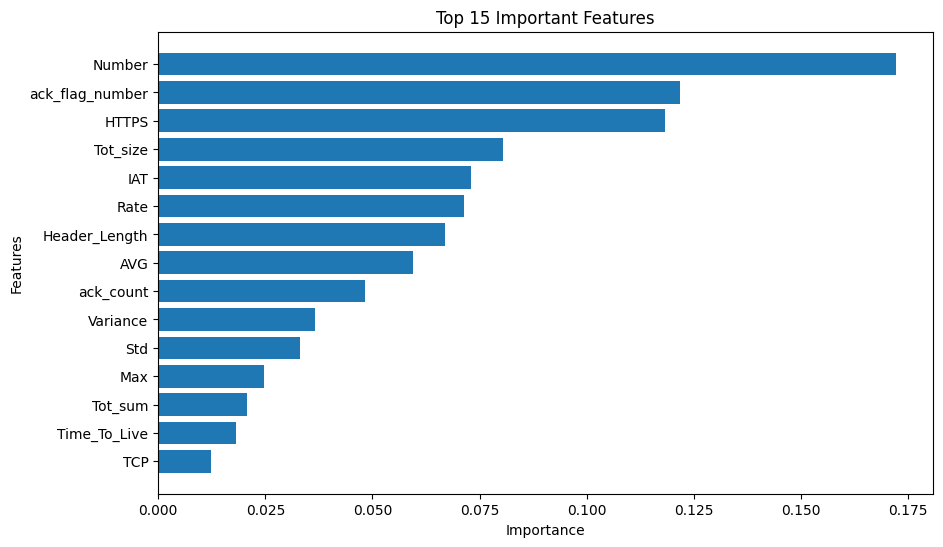

In [20]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10,6))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.ylabel("Features")

plt.title("Top 15 Important Features")

plt.show()

In [21]:
#STEP 1 — Select Top Features
top_5 = feature_importance.head(5)['Feature'].tolist()

top_10 = feature_importance.head(10)['Feature'].tolist()

top_15 = feature_importance.head(15)['Feature'].tolist()

print(top_5)
print(top_10)
print(top_15)

['Number', 'ack_flag_number', 'HTTPS', 'Tot_size', 'IAT']
['Number', 'ack_flag_number', 'HTTPS', 'Tot_size', 'IAT', 'Rate', 'Header_Length', 'AVG', 'ack_count', 'Variance']
['Number', 'ack_flag_number', 'HTTPS', 'Tot_size', 'IAT', 'Rate', 'Header_Length', 'AVG', 'ack_count', 'Variance', 'Std', 'Max', 'Tot_sum', 'Time_To_Live', 'TCP']


In [22]:
#Train Using ONLY Top 5 Features
X_train_5 = X_train[top_5]
X_test_5 = X_test[top_5]

In [23]:
#Train Model
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import time

start = time.time()

rf_5 = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_5.fit(X_train_5, y_train)

end = time.time()

y_pred_5 = rf_5.predict(X_test_5)

print("Training Time:", end - start)

print("Accuracy:", accuracy_score(y_test, y_pred_5))

print("F1 Score:", f1_score(y_test, y_pred_5))

Training Time: 7.303244113922119
Accuracy: 0.98475
F1 Score: 0.9845561800597499


In [24]:
#Train Using ONLY Top 10 Features
X_train_10 = X_train[top_10]
X_test_10 = X_test[top_10]

In [25]:
start = time.time()

rf_10 = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_10.fit(X_train_10, y_train)

end = time.time()

y_pred_10 = rf_10.predict(X_test_10)

print("Training Time:", end - start)

print("Accuracy:", accuracy_score(y_test, y_pred_10))

print("F1 Score:", f1_score(y_test, y_pred_10))

Training Time: 11.524062871932983
Accuracy: 0.98575
F1 Score: 0.9855688895640285


In [26]:
#Train Using ONLY Top 15 Features
X_train_15 = X_train[top_15]
X_test_15 = X_test[top_15]

In [27]:
start = time.time()

rf_15 = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_15.fit(X_train_15, y_train)

end = time.time()

y_pred_15 = rf_15.predict(X_test_15)

print("Training Time:", end - start)

print("Accuracy:", accuracy_score(y_test, y_pred_15))

print("F1 Score:", f1_score(y_test, y_pred_15))


Training Time: 12.164984464645386
Accuracy: 0.98735
F1 Score: 0.9872060682680152


In [28]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, y_pred_10))
print(confusion_matrix(y_test, y_pred_10))

              precision    recall  f1-score   support

           0       0.97      1.00      0.99     20000
           1       1.00      0.97      0.99     20000

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

[[19966    34]
 [  536 19464]]


In [29]:
#Inference Time
import time

start = time.time()

y_pred_10 = rf_10.predict(X_test_10)

end = time.time()

print("Inference Time:", end - start)

Inference Time: 0.1784975528717041


In [30]:
#Model Size
import joblib
import os

joblib.dump(rf_10, "rf_10.pkl")

print(
    os.path.getsize("rf_10.pkl") / 1024 / 1024,
    "MB"
)

19.891213417053223 MB


In [31]:
#Inference Time
import time

start = time.time()

y_pred = rf.predict(X_test)

end = time.time()

print("Inference Time:", end - start)

Inference Time: 0.2041337490081787


In [32]:
#Model Size
import joblib
import os

joblib.dump(rf, "rf.pkl")

print(
    os.path.getsize("rf.pkl") / 1024 / 1024,
    "MB"
)

14.490044593811035 MB


In [33]:
pwd

'G:\\IoT_IDS_Research'

In [34]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, y_pred_15))
print(confusion_matrix(y_test, y_pred_15))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99     20000
           1       1.00      0.98      0.99     20000

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

[[19972    28]
 [  478 19522]]


In [35]:
# !pip install river

In [36]:
# !pip install numpy==2.2.6

In [37]:
import numpy
# import river

print(numpy.__version__)

2.2.6


In [38]:
# from river import drift

# print("River installed successfully")

In [39]:
import os
os.chdir(r'G:\IoT_IDS_Research')

# Classifier Comparison Experiment

This section compares the proposed Random Forest Top-15 model with other machine learning classifiers using the same balanced CICIoT2023 train-test split. The goal is to strengthen the paper by showing that the proposed model is competitive not only against the full Random Forest baseline but also against common ML classifiers.

In [40]:

# ============================================================
# CLASSIFIER COMPARISON EXPERIMENT
# Purpose:
# Compare the proposed RF Top-15 model with other ML classifiers
# using the same balanced CICIoT2023 train-test split.
# ============================================================

import os
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Ensure labels are one-dimensional arrays
y_train_arr = np.ravel(y_train)
y_test_arr = np.ravel(y_test)

# Ensure Top-15 data exists
try:
    X_train_15
    X_test_15
except NameError:
    X_train_15 = X_train[top_15]
    X_test_15 = X_test[top_15]

print("Training set:", X_train_15.shape)
print("Testing set:", X_test_15.shape)
print("Class distribution in training set:")
print(pd.Series(y_train_arr).value_counts().sort_index())
print("Class distribution in testing set:")
print(pd.Series(y_test_arr).value_counts().sort_index())


Training set: (160000, 15)
Testing set: (40000, 15)
Class distribution in training set:
0    80000
1    80000
Name: count, dtype: int64
Class distribution in testing set:
0    20000
1    20000
Name: count, dtype: int64


In [41]:

# ============================================================
# 1. Define comparison classifiers
# ============================================================

models = {
    "Decision Tree Top-15": DecisionTreeClassifier(
        max_depth=20,
        random_state=42
    ),

    "Extra Trees Top-15": ExtraTreesClassifier(
        n_estimators=100,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ),

    "Random Forest Top-15": RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ),

    "Logistic Regression Top-15": LogisticRegression(
        max_iter=1000,
        solver="saga",
        n_jobs=-1,
        random_state=42
    ),

    "Gaussian NB Top-15": GaussianNB(),

    "HistGradientBoosting Top-15": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    )
}

# Optional: XGBoost, only if installed.
try:
    from xgboost import XGBClassifier

    models["XGBoost Top-15"] = XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    print("XGBoost detected and added.")
except Exception as e:
    print("XGBoost not available. Skipping XGBoost.")
    print("Reason:", e)

# Optional: LightGBM, only if installed.
try:
    from lightgbm import LGBMClassifier

    models["LightGBM Top-15"] = LGBMClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=-1,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )

    print("LightGBM detected and added.")
except Exception as e:
    print("LightGBM not available. Skipping LightGBM.")
    print("Reason:", e)

print("Models selected for comparison:")
for name in models:
    print("-", name)


XGBoost not available. Skipping XGBoost.
Reason: No module named 'xgboost'
LightGBM not available. Skipping LightGBM.
Reason: No module named 'lightgbm'
Models selected for comparison:
- Decision Tree Top-15
- Extra Trees Top-15
- Random Forest Top-15
- Logistic Regression Top-15
- Gaussian NB Top-15
- HistGradientBoosting Top-15


In [42]:

# ============================================================
# 2. Evaluation function
# ============================================================

def evaluate_model(model_name, model, Xtr, Xte, ytr, yte, save_model=True):
    """
    Train and evaluate one classifier.
    Returns a dictionary containing performance and efficiency metrics.
    """
    start_train = time.time()
    model.fit(Xtr, ytr)
    train_time = time.time() - start_train

    start_pred = time.time()
    y_pred = model.predict(Xte)
    inference_time = time.time() - start_pred

    # Confusion matrix format:
    # [[TN, FP],
    #  [FN, TP]]
    tn, fp, fn, tp = confusion_matrix(yte, y_pred).ravel()

    acc = accuracy_score(yte, y_pred)
    prec = precision_score(yte, y_pred, zero_division=0)
    rec = recall_score(yte, y_pred, zero_division=0)
    f1 = f1_score(yte, y_pred, zero_division=0)
    bal_acc = balanced_accuracy_score(yte, y_pred)
    mcc = matthews_corrcoef(yte, y_pred)

    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0

    # ROC-AUC: use predict_proba if available, otherwise decision_function.
    roc_auc = np.nan
    try:
        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(Xte)[:, 1]
            roc_auc = roc_auc_score(yte, y_score)
        elif hasattr(model, "decision_function"):
            y_score = model.decision_function(Xte)
            roc_auc = roc_auc_score(yte, y_score)
    except Exception:
        roc_auc = np.nan

    model_size_mb = np.nan
    if save_model:
        os.makedirs("outputs/models", exist_ok=True)
        safe_name = model_name.lower().replace(" ", "_").replace("-", "_")
        model_path = f"outputs/models/{safe_name}.pkl"
        joblib.dump(model, model_path)
        model_size_mb = os.path.getsize(model_path) / 1024 / 1024

    return {
        "Model": model_name,
        "Features": Xtr.shape[1],
        "Accuracy": acc,
        "Precision_Attack": prec,
        "Recall_Attack": rec,
        "F1_Attack": f1,
        "Balanced_Accuracy": bal_acc,
        "MCC": mcc,
        "ROC_AUC": roc_auc,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "FPR": fpr,
        "FNR": fnr,
        "Training_Time_sec": train_time,
        "Inference_Time_sec": inference_time,
        "Model_Size_MB": model_size_mb
    }


# ============================================================
# 3. Run comparison on Top-15 feature subset
# ============================================================

results = []

for model_name, model in models.items():
    print("\nTraining:", model_name)
    result = evaluate_model(
        model_name=model_name,
        model=model,
        Xtr=X_train_15,
        Xte=X_test_15,
        ytr=y_train_arr,
        yte=y_test_arr,
        save_model=True
    )
    results.append(result)

    print(
        f"Accuracy={result['Accuracy']:.5f}, "
        f"F1={result['F1_Attack']:.5f}, "
        f"FPR={result['FPR']:.5f}, "
        f"Train={result['Training_Time_sec']:.2f}s, "
        f"Inference={result['Inference_Time_sec']:.4f}s"
    )

comparison_df = pd.DataFrame(results)

# Sort by F1-score and then false positive rate
comparison_df = comparison_df.sort_values(
    by=["F1_Attack", "FPR"],
    ascending=[False, True]
).reset_index(drop=True)

os.makedirs("outputs", exist_ok=True)
comparison_df.to_csv("outputs/classifier_comparison_top15.csv", index=False)

print("\nFinal Classifier Comparison Table:")
display(comparison_df)

print("\nSaved: outputs/classifier_comparison_top15.csv")



Training: Decision Tree Top-15
Accuracy=0.98315, F1=0.98307, FPR=0.01190, Train=3.30s, Inference=0.0158s

Training: Extra Trees Top-15
Accuracy=0.98595, F1=0.98576, FPR=0.00080, Train=4.62s, Inference=0.2104s

Training: Random Forest Top-15
Accuracy=0.98735, F1=0.98721, FPR=0.00140, Train=11.95s, Inference=0.1987s

Training: Logistic Regression Top-15


C:\Users\Hp\.conda\envs\iotids\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\Hp\.conda\envs\iotids\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Accuracy=0.98298, F1=0.98269, FPR=0.00035, Train=123.47s, Inference=0.0080s

Training: Gaussian NB Top-15
Accuracy=0.97342, F1=0.97329, FPR=0.02150, Train=0.10s, Inference=0.0238s

Training: HistGradientBoosting Top-15
Accuracy=0.98752, F1=0.98738, FPR=0.00135, Train=10.06s, Inference=0.2456s

Final Classifier Comparison Table:


,Model,Features,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,Balanced_Accuracy,MCC,ROC_AUC,TN,FP,FN,TP,FPR,FNR,Training_Time_sec,Inference_Time_sec,Model_Size_MB
0,HistGradientBoosting Top-15,15,0.987525,0.998619,0.97640,0.987385,0.987525,0.975291,0.996259,19973,27,472,19528,0.00135,0.02360,10.061742,0.245557,0.372292
1,Random Forest Top-15,15,0.987350,0.998568,0.97610,0.987206,0.987350,0.974947,0.996450,19972,28,478,19522,0.00140,0.02390,11.949391,0.198745,17.804467
2,Extra Trees Top-15,15,0.985950,0.999178,0.97270,0.985761,0.985950,0.972241,0.995911,19984,16,546,19454,0.00080,0.02730,4.621588,0.210360,37.555139
3,Decision Tree Top-15,15,0.983150,0.987981,0.97820,0.983066,0.983150,0.966347,0.984647,19762,238,436,19564,0.01190,0.02180,3.297460,0.015825,0.193170
4,Logistic Regression Top-15,15,0.982975,0.999638,0.96630,0.982686,0.982975,0.966488,0.992165,19993,7,674,19326,0.00035,0.03370,123.472823,0.007953,0.001327
5,Gaussian NB Top-15,15,0.973425,0.978280,0.96835,0.973289,0.973425,0.946899,0.990279,19570,430,633,19367,0.02150,0.03165,0.104210,0.023798,0.001578



Saved: outputs/classifier_comparison_top15.csv


In [43]:

# ============================================================
# 4. Add Full Random Forest baseline to comparison
# ============================================================

rf_full_for_comparison = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_full_result = evaluate_model(
    model_name="Random Forest Full-39",
    model=rf_full_for_comparison,
    Xtr=X_train,
    Xte=X_test,
    ytr=y_train_arr,
    yte=y_test_arr,
    save_model=True
)

full_plus_top15_df = pd.concat(
    [pd.DataFrame([rf_full_result]), comparison_df],
    ignore_index=True
)

full_plus_top15_df.to_csv(
    "outputs/classifier_comparison_full_and_top15.csv",
    index=False
)

print("Full RF baseline added.")
display(full_plus_top15_df)

print("\nSaved: outputs/classifier_comparison_full_and_top15.csv")


Full RF baseline added.


,Model,Features,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,Balanced_Accuracy,MCC,ROC_AUC,TN,FP,FN,TP,FPR,FNR,Training_Time_sec,Inference_Time_sec,Model_Size_MB
0,Random Forest Full-39,39,0.988725,0.999132,0.97830,0.988606,0.988725,0.977663,0.996830,19983,17,434,19566,0.00085,0.02170,12.412934,0.217311,14.490045
1,HistGradientBoosting Top-15,15,0.987525,0.998619,0.97640,0.987385,0.987525,0.975291,0.996259,19973,27,472,19528,0.00135,0.02360,10.061742,0.245557,0.372292
2,Random Forest Top-15,15,0.987350,0.998568,0.97610,0.987206,0.987350,0.974947,0.996450,19972,28,478,19522,0.00140,0.02390,11.949391,0.198745,17.804467
3,Extra Trees Top-15,15,0.985950,0.999178,0.97270,0.985761,0.985950,0.972241,0.995911,19984,16,546,19454,0.00080,0.02730,4.621588,0.210360,37.555139
4,Decision Tree Top-15,15,0.983150,0.987981,0.97820,0.983066,0.983150,0.966347,0.984647,19762,238,436,19564,0.01190,0.02180,3.297460,0.015825,0.193170
5,Logistic Regression Top-15,15,0.982975,0.999638,0.96630,0.982686,0.982975,0.966488,0.992165,19993,7,674,19326,0.00035,0.03370,123.472823,0.007953,0.001327
6,Gaussian NB Top-15,15,0.973425,0.978280,0.96835,0.973289,0.973425,0.946899,0.990279,19570,430,633,19367,0.02150,0.03165,0.104210,0.023798,0.001578



Saved: outputs/classifier_comparison_full_and_top15.csv


In [44]:

# ============================================================
# 5. Print classification report for the best model
# ============================================================

best_model_name = comparison_df.loc[0, "Model"]
print("Best model according to F1-score:", best_model_name)

# Re-train the best model for detailed report
best_model = models[best_model_name]
best_model.fit(X_train_15, y_train_arr)
best_pred = best_model.predict(X_test_15)

print("\nClassification Report:")
print(classification_report(y_test_arr, best_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test_arr, best_pred))


Best model according to F1-score: HistGradientBoosting Top-15

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99     20000
           1       1.00      0.98      0.99     20000

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

Confusion Matrix:
[[19973    27]
 [  472 19528]]


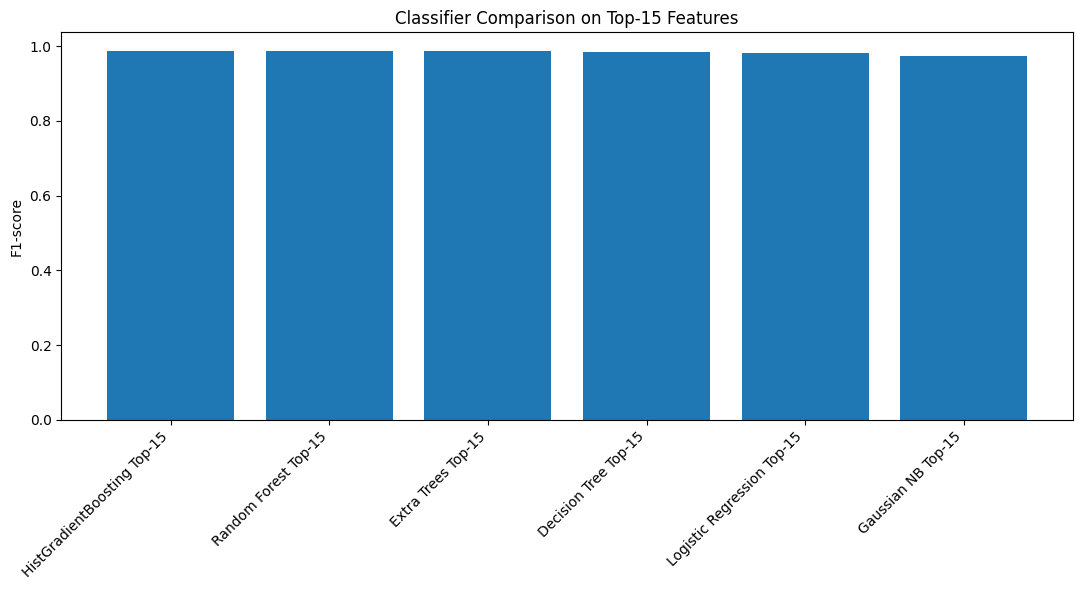

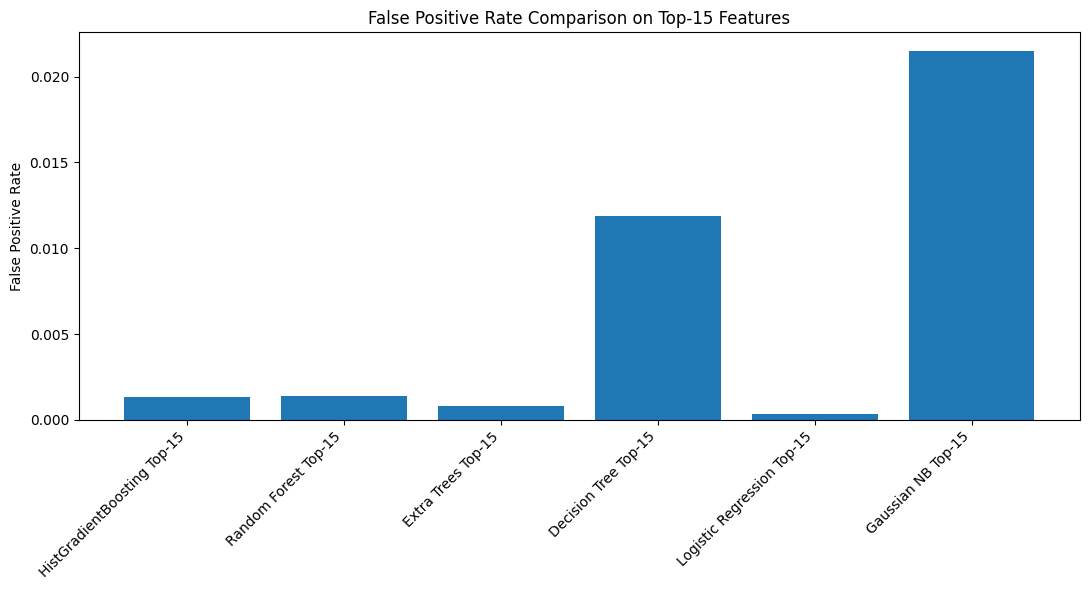

Saved figures:
- outputs/classifier_comparison_f1_top15.png
- outputs/classifier_comparison_fpr_top15.png


In [45]:

# ============================================================
# 6. Plot comparison figures
# ============================================================

import matplotlib.pyplot as plt

plot_df = comparison_df.copy()

plt.figure(figsize=(11, 6))
plt.bar(plot_df["Model"], plot_df["F1_Attack"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("F1-score")
plt.title("Classifier Comparison on Top-15 Features")
plt.tight_layout()
plt.savefig("outputs/classifier_comparison_f1_top15.png", dpi=300)
plt.show()

plt.figure(figsize=(11, 6))
plt.bar(plot_df["Model"], plot_df["FPR"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("False Positive Rate")
plt.title("False Positive Rate Comparison on Top-15 Features")
plt.tight_layout()
plt.savefig("outputs/classifier_comparison_fpr_top15.png", dpi=300)
plt.show()

print("Saved figures:")
print("- outputs/classifier_comparison_f1_top15.png")
print("- outputs/classifier_comparison_fpr_top15.png")


In [46]:

# ============================================================
# 7. Generate paper-ready table with percentages
# ============================================================

paper_table = full_plus_top15_df.copy()

paper_table["Accuracy (%)"] = paper_table["Accuracy"] * 100
paper_table["Precision (%)"] = paper_table["Precision_Attack"] * 100
paper_table["Recall (%)"] = paper_table["Recall_Attack"] * 100
paper_table["F1-score (%)"] = paper_table["F1_Attack"] * 100
paper_table["FPR (%)"] = paper_table["FPR"] * 100
paper_table["FNR (%)"] = paper_table["FNR"] * 100

paper_table = paper_table[[
    "Model",
    "Features",
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-score (%)",
    "Balanced_Accuracy",
    "MCC",
    "FPR (%)",
    "FNR (%)",
    "Training_Time_sec",
    "Inference_Time_sec",
    "Model_Size_MB"
]]

paper_table.to_csv("outputs/paper_ready_classifier_comparison.csv", index=False)

display(paper_table)

print("Saved: outputs/paper_ready_classifier_comparison.csv")


,Model,Features,Accuracy (%),Precision (%),Recall (%),F1-score (%),Balanced_Accuracy,MCC,FPR (%),FNR (%),Training_Time_sec,Inference_Time_sec,Model_Size_MB
0,Random Forest Full-39,39,98.8725,99.913190,97.830,98.860622,0.988725,0.977663,0.085,2.170,12.412934,0.217311,14.490045
1,HistGradientBoosting Top-15,15,98.7525,99.861928,97.640,98.738465,0.987525,0.975291,0.135,2.360,10.061742,0.245557,0.372292
2,Random Forest Top-15,15,98.7350,99.856777,97.610,98.720607,0.987350,0.974947,0.140,2.390,11.949391,0.198745,17.804467
3,Extra Trees Top-15,15,98.5950,99.917822,97.270,98.576134,0.985950,0.972241,0.080,2.730,4.621588,0.210360,37.555139
4,Decision Tree Top-15,15,98.3150,98.798101,97.820,98.306618,0.983150,0.966347,1.190,2.180,3.297460,0.015825,0.193170
5,Logistic Regression Top-15,15,98.2975,99.963792,96.630,98.268629,0.982975,0.966488,0.035,3.370,123.472823,0.007953,0.001327
6,Gaussian NB Top-15,15,97.3425,97.827954,96.835,97.328944,0.973425,0.946899,2.150,3.165,0.104210,0.023798,0.001578


Saved: outputs/paper_ready_classifier_comparison.csv


In [47]:

# ============================================================
# 8. Export LaTeX table for paper
# ============================================================

latex_ready = paper_table.copy()

# Round values for paper
for col in latex_ready.columns:
    if col != "Model":
        latex_ready[col] = pd.to_numeric(latex_ready[col], errors="ignore")

rounded = latex_ready.round({
    "Accuracy (%)": 2,
    "Precision (%)": 2,
    "Recall (%)": 2,
    "F1-score (%)": 2,
    "Balanced_Accuracy": 4,
    "MCC": 4,
    "FPR (%)": 4,
    "FNR (%)": 4,
    "Training_Time_sec": 3,
    "Inference_Time_sec": 4,
    "Model_Size_MB": 2
})

latex_table = rounded.to_latex(
    index=False,
    escape=True,
    caption="Comparative Performance of Machine Learning Classifiers on CICIoT2023",
    label="tab:classifier_comparison"
)

with open("outputs/classifier_comparison_table.tex", "w", encoding="utf-8") as f:
    f.write(latex_table)

print(latex_table)
print("\nSaved: outputs/classifier_comparison_table.tex")


C:\Users\Hp\AppData\Local\Temp\ipykernel_21052\1983140205.py:10: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  latex_ready[col] = pd.to_numeric(latex_ready[col], errors="ignore")


\begin{table}
\caption{Comparative Performance of Machine Learning Classifiers on CICIoT2023}
\label{tab:classifier_comparison}
\begin{tabular}{lrrrrrrrrrrrr}
\toprule
Model & Features & Accuracy (\%) & Precision (\%) & Recall (\%) & F1-score (\%) & Balanced\_Accuracy & MCC & FPR (\%) & FNR (\%) & Training\_Time\_sec & Inference\_Time\_sec & Model\_Size\_MB \\
\midrule
Random Forest Full-39 & 39 & 98.870000 & 99.910000 & 97.830000 & 98.860000 & 0.988700 & 0.977700 & 0.085000 & 2.170000 & 12.413000 & 0.217300 & 14.490000 \\
HistGradientBoosting Top-15 & 15 & 98.750000 & 99.860000 & 97.640000 & 98.740000 & 0.987500 & 0.975300 & 0.135000 & 2.360000 & 10.062000 & 0.245600 & 0.370000 \\
Random Forest Top-15 & 15 & 98.740000 & 99.860000 & 97.610000 & 98.720000 & 0.987400 & 0.974900 & 0.140000 & 2.390000 & 11.949000 & 0.198700 & 17.800000 \\
Extra Trees Top-15 & 15 & 98.600000 & 99.920000 & 97.270000 & 98.580000 & 0.986000 & 0.972200 & 0.080000 & 2.730000 & 4.622000 & 0.210400 & 37.560000 \\


# Multiclass Attack Category Classification Extension

This section implements the recommended Phase 1 to Phase 5 multiclass extension.

The objective is to move from binary detection:

`BENIGN vs ATTACK`

to broad attack-family classification such as:

`BENIGN`, `DDoS`, `DoS`, `Mirai`, `Reconnaissance`, `Spoofing`, `Web/Malware`, `Brute Force`, `Other`.

The code below:
1. loads the processed balanced dataset,
2. verifies or creates broad attack-category labels,
3. builds a class-aware multiclass sample,
4. trains full-feature and Top-15 feature classifiers,
5. evaluates multiclass performance using macro F1, weighted F1, balanced accuracy, MCC, and ROC-AUC,
6. exports result tables, confusion matrices, and LaTeX tables for the paper.


In [48]:

# ============================================================
# MULTICLASS EXTENSION - PHASE 1
# Load processed dataset and inspect attack-category labels
# ============================================================

import os
import time
import joblib
import numpy as np
import pandas as pd

from pathlib import Path

# IMPORTANT:
# Run this notebook from your main project directory:
# G:\IoT_IDS_Research
#
# If required, uncomment and modify:
# os.chdir(r"G:\IoT_IDS_Research")

DATA_PATH = Path("data/processed/final_sample_200000.csv")
OUTPUT_DIR = Path("outputs/multiclass")
MODEL_DIR = OUTPUT_DIR / "models"
FIG_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Please run the preprocessing pipeline first "
        "or update DATA_PATH to the location of final_sample_200000.csv."
    )

df_mc = pd.read_csv(DATA_PATH)

print("Loaded dataset:", DATA_PATH)
print("Shape:", df_mc.shape)
print("Columns:", df_mc.columns.tolist()[:10], "...")

# ------------------------------------------------------------
# Create broad attack categories if Attack_Category is missing
# ------------------------------------------------------------

def map_attack_category(label):
    """
    Maps CICIoT2023 fine-grained labels into broad attack categories.
    The function is intentionally rule-based so it can handle labels
    such as DDoS-UDP_Flood, DoS-TCP_Flood, Mirai-greeth_flood, etc.
    """
    label_str = str(label).strip()
    label_low = label_str.lower()

    if label_low in ["benign", "normal"]:
        return "BENIGN"
    if "ddos" in label_low:
        return "DDoS"
    if "dos" in label_low:
        return "DoS"
    if "mirai" in label_low:
        return "Mirai"
    if "recon" in label_low or "scan" in label_low or "osscan" in label_low or "portscan" in label_low:
        return "Reconnaissance"
    if "spoof" in label_low:
        return "Spoofing"
    if "brute" in label_low or "password" in label_low:
        return "Brute Force"
    if "web" in label_low or "sql" in label_low or "xss" in label_low or "upload" in label_low or "injection" in label_low:
        return "Web/Malware"
    if "malware" in label_low or "backdoor" in label_low or "ransom" in label_low:
        return "Web/Malware"
    return "Other"

if "Attack_Category" not in df_mc.columns:
    if "Label" not in df_mc.columns:
        raise ValueError("Neither Attack_Category nor Label column is available.")
    df_mc["Attack_Category"] = df_mc["Label"].apply(map_attack_category)

print("\nAttack category distribution:")
category_counts = df_mc["Attack_Category"].value_counts()
print(category_counts)

print("\nAttack category distribution (%):")
print((df_mc["Attack_Category"].value_counts(normalize=True) * 100).round(3))

category_counts.to_csv(OUTPUT_DIR / "attack_category_distribution.csv")
print("\nSaved:", OUTPUT_DIR / "attack_category_distribution.csv")


Loaded dataset: data\processed\final_sample_200000.csv
Shape: (200000, 42)
Columns: ['Header_Length', 'Protocol_Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number'] ...

Attack category distribution:
Attack_Category
BENIGN                100000
DDOS                   69521
DOS                    19238
MIRAI                   7693
SPOOFING                1346
VULNERABILITY_SCAN      1108
RECON                    978
WEB_OR_MALWARE            84
BRUTEFORCE                32
Name: count, dtype: int64

Attack category distribution (%):
Attack_Category
BENIGN                50.000
DDOS                  34.760
DOS                    9.619
MIRAI                  3.846
SPOOFING               0.673
VULNERABILITY_SCAN     0.554
RECON                  0.489
WEB_OR_MALWARE         0.042
BRUTEFORCE             0.016
Name: proportion, dtype: float64

Saved: outputs\multiclass\attack_category_distribution.csv


In [49]:

# ============================================================
# MULTICLASS EXTENSION - PHASE 2
# Build class-aware multiclass sample
# ============================================================

# Configuration
# Keep broad classes with at least MIN_CLASS_SAMPLES.
# Rare categories can be merged into Other or dropped.
MIN_CLASS_SAMPLES = 1000
MAX_SAMPLES_PER_CLASS = 30000
RANDOM_STATE = 42

# Clean category names
df_mc["Attack_Category"] = df_mc["Attack_Category"].astype(str).str.strip()

# Merge very rare non-BENIGN classes into Other
counts_before = df_mc["Attack_Category"].value_counts()
rare_classes = [
    cls for cls, cnt in counts_before.items()
    if cnt < MIN_CLASS_SAMPLES and cls != "BENIGN"
]

if rare_classes:
    print("Merging rare classes into Other:", rare_classes)
    df_mc.loc[df_mc["Attack_Category"].isin(rare_classes), "Attack_Category"] = "Other"

counts_after_merge = df_mc["Attack_Category"].value_counts()
print("\nCounts after rare-class merge:")
print(counts_after_merge)

# Remove classes still too small after merging, except when needed
valid_classes = counts_after_merge[counts_after_merge >= MIN_CLASS_SAMPLES].index.tolist()
df_valid = df_mc[df_mc["Attack_Category"].isin(valid_classes)].copy()

print("\nClasses retained for multiclass classification:")
print(df_valid["Attack_Category"].value_counts())

# Choose a balanced sample size per class.
# This avoids one huge class dominating macro metrics.
min_available = df_valid["Attack_Category"].value_counts().min()
target_per_class = min(MAX_SAMPLES_PER_CLASS, min_available)

print("\nTarget samples per class:", target_per_class)

balanced_parts = []
for cls, group in df_valid.groupby("Attack_Category"):
    sampled = group.sample(
        n=target_per_class,
        random_state=RANDOM_STATE,
        replace=False
    )
    balanced_parts.append(sampled)

df_multi_balanced = pd.concat(balanced_parts, ignore_index=True)
df_multi_balanced = df_multi_balanced.sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)

print("\nBalanced multiclass dataset shape:", df_multi_balanced.shape)
print(df_multi_balanced["Attack_Category"].value_counts())

df_multi_balanced.to_csv(OUTPUT_DIR / "multiclass_balanced_sample.csv", index=False)
print("\nSaved:", OUTPUT_DIR / "multiclass_balanced_sample.csv")


Merging rare classes into Other: ['RECON', 'WEB_OR_MALWARE', 'BRUTEFORCE']

Counts after rare-class merge:
Attack_Category
BENIGN                100000
DDOS                   69521
DOS                    19238
MIRAI                   7693
SPOOFING                1346
VULNERABILITY_SCAN      1108
Other                   1094
Name: count, dtype: int64

Classes retained for multiclass classification:
Attack_Category
BENIGN                100000
DDOS                   69521
DOS                    19238
MIRAI                   7693
SPOOFING                1346
VULNERABILITY_SCAN      1108
Other                   1094
Name: count, dtype: int64

Target samples per class: 1094

Balanced multiclass dataset shape: (7658, 42)
Attack_Category
VULNERABILITY_SCAN    1094
MIRAI                 1094
SPOOFING              1094
DOS                   1094
Other                 1094
DDOS                  1094
BENIGN                1094
Name: count, dtype: int64

Saved: outputs\multiclass\multiclass_balanc

In [50]:

# ============================================================
# MULTICLASS EXTENSION - PHASE 3
# Prepare full-feature and Top-15 feature train-test datasets
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Top-15 features from the binary IDS experiment
top_15_features = [
    "Number",
    "ack_flag_number",
    "HTTPS",
    "Tot_size",
    "Rate",
    "Header_Length",
    "IAT",
    "AVG",
    "ack_count",
    "Variance",
    "Std",
    "Max",
    "Tot_sum",
    "Time_To_Live",
    "Min"
]

# Remove non-feature columns
non_feature_cols = [
    "Label",
    "Binary_Label",
    "Attack_Category"
]

available_non_features = [c for c in non_feature_cols if c in df_multi_balanced.columns]

X_multi_full = df_multi_balanced.drop(columns=available_non_features)
X_multi_full = X_multi_full.select_dtypes(include=[np.number]).copy()

missing_top15 = [c for c in top_15_features if c not in X_multi_full.columns]
if missing_top15:
    raise ValueError(
        "The following Top-15 features are missing from the dataset: "
        + ", ".join(missing_top15)
    )

X_multi_top15 = X_multi_full[top_15_features].copy()

le_multi = LabelEncoder()
y_multi = le_multi.fit_transform(df_multi_balanced["Attack_Category"])

class_mapping = pd.DataFrame({
    "Encoded_Label": range(len(le_multi.classes_)),
    "Attack_Category": le_multi.classes_
})
class_mapping.to_csv(OUTPUT_DIR / "multiclass_label_mapping.csv", index=False)

print("Class mapping:")
display(class_mapping)

# Train-test split
X_train_multi_full, X_test_multi_full, y_train_multi, y_test_multi = train_test_split(
    X_multi_full,
    y_multi,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_multi
)

X_train_multi_15, X_test_multi_15, _, _ = train_test_split(
    X_multi_top15,
    y_multi,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_multi
)

# Scaling
scaler_full_multi = StandardScaler()
X_train_multi_full_scaled = scaler_full_multi.fit_transform(X_train_multi_full)
X_test_multi_full_scaled = scaler_full_multi.transform(X_test_multi_full)

scaler_15_multi = StandardScaler()
X_train_multi_15_scaled = scaler_15_multi.fit_transform(X_train_multi_15)
X_test_multi_15_scaled = scaler_15_multi.transform(X_test_multi_15)

print("Full-feature train shape:", X_train_multi_full_scaled.shape)
print("Full-feature test shape:", X_test_multi_full_scaled.shape)
print("Top-15 train shape:", X_train_multi_15_scaled.shape)
print("Top-15 test shape:", X_test_multi_15_scaled.shape)

print("\nTraining class distribution:")
print(pd.Series(y_train_multi).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test_multi).value_counts().sort_index())


Class mapping:


,Encoded_Label,Attack_Category
0,0,BENIGN
1,1,DDOS
2,2,DOS
3,3,MIRAI
4,4,Other
5,5,SPOOFING
6,6,VULNERABILITY_SCAN


Full-feature train shape: (6126, 39)
Full-feature test shape: (1532, 39)
Top-15 train shape: (6126, 15)
Top-15 test shape: (1532, 15)

Training class distribution:
0    876
1    875
2    875
3    875
4    875
5    875
6    875
Name: count, dtype: int64

Testing class distribution:
0    218
1    219
2    219
3    219
4    219
5    219
6    219
Name: count, dtype: int64


In [52]:

# ============================================================
# MULTICLASS EXTENSION - PHASE 4
# Define multiclass classifiers and evaluation function
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.preprocessing import label_binarize

multiclass_models_top15 = {
    "Decision Tree Top-15": DecisionTreeClassifier(
        max_depth=20,
        random_state=RANDOM_STATE
    ),

    "Extra Trees Top-15": ExtraTreesClassifier(
        n_estimators=100,
        max_depth=20,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Random Forest Top-15": RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    # "Logistic Regression Top-15": LogisticRegression(
    #     max_iter=1000,
    #     solver="saga",
    #     multi_class="auto",
    #     n_jobs=-1,
    #     random_state=RANDOM_STATE
    # ),

    "Logistic Regression Top-15": LogisticRegression(
    max_iter=1000,
    solver="lbfgs",
    n_jobs=-1,
    random_state=42
    ),

    "Gaussian NB Top-15": GaussianNB(),

    "HistGradientBoosting Top-15": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=RANDOM_STATE
    )
}

# Optional XGBoost
try:
    from xgboost import XGBClassifier
    multiclass_models_top15["XGBoost Top-15"] = XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="mlogloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    print("XGBoost detected and added.")
except Exception as e:
    print("XGBoost not available. Skipping XGBoost.")
    print("Reason:", e)

# Optional LightGBM
try:
    from lightgbm import LGBMClassifier
    multiclass_models_top15["LightGBM Top-15"] = LGBMClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1
    )
    print("LightGBM detected and added.")
except Exception as e:
    print("LightGBM not available. Skipping LightGBM.")
    print("Reason:", e)

print("Multiclass models selected:")
for name in multiclass_models_top15:
    print("-", name)


def multiclass_roc_auc(model, Xte, yte, n_classes):
    """
    Computes multiclass ROC-AUC using one-vs-rest strategy.
    Returns macro and weighted ROC-AUC when probabilities/scores are available.
    """
    try:
        y_bin = label_binarize(yte, classes=np.arange(n_classes))

        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(Xte)
        elif hasattr(model, "decision_function"):
            y_score = model.decision_function(Xte)
        else:
            return np.nan, np.nan

        if y_score.shape[1] != n_classes:
            return np.nan, np.nan

        roc_macro = roc_auc_score(
            y_bin,
            y_score,
            average="macro",
            multi_class="ovr"
        )

        roc_weighted = roc_auc_score(
            y_bin,
            y_score,
            average="weighted",
            multi_class="ovr"
        )

        return roc_macro, roc_weighted

    except Exception:
        return np.nan, np.nan


def evaluate_multiclass_model(model_name, model, Xtr, Xte, ytr, yte, feature_count):
    """
    Trains and evaluates one multiclass classifier.
    """
    start_train = time.time()
    model.fit(Xtr, ytr)
    train_time = time.time() - start_train

    start_pred = time.time()
    y_pred = model.predict(Xte)
    inference_time = time.time() - start_pred

    acc = accuracy_score(yte, y_pred)
    macro_precision = precision_score(yte, y_pred, average="macro", zero_division=0)
    macro_recall = recall_score(yte, y_pred, average="macro", zero_division=0)
    macro_f1 = f1_score(yte, y_pred, average="macro", zero_division=0)

    weighted_precision = precision_score(yte, y_pred, average="weighted", zero_division=0)
    weighted_recall = recall_score(yte, y_pred, average="weighted", zero_division=0)
    weighted_f1 = f1_score(yte, y_pred, average="weighted", zero_division=0)

    bal_acc = balanced_accuracy_score(yte, y_pred)
    mcc = matthews_corrcoef(yte, y_pred)

    roc_auc_macro, roc_auc_weighted = multiclass_roc_auc(
        model,
        Xte,
        yte,
        n_classes=len(le_multi.classes_)
    )

    safe_name = model_name.lower().replace(" ", "_").replace("-", "_")
    model_path = MODEL_DIR / f"{safe_name}.pkl"
    joblib.dump(model, model_path)
    model_size_mb = os.path.getsize(model_path) / 1024 / 1024

    cm = confusion_matrix(yte, y_pred)
    pd.DataFrame(
        cm,
        index=le_multi.classes_,
        columns=le_multi.classes_
    ).to_csv(OUTPUT_DIR / f"confusion_matrix_{safe_name}.csv")

    report_dict = classification_report(
        yte,
        y_pred,
        target_names=le_multi.classes_,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(report_dict).transpose().to_csv(
        OUTPUT_DIR / f"classification_report_{safe_name}.csv"
    )

    return {
        "Model": model_name,
        "Features": feature_count,
        "Accuracy": acc,
        "Macro_Precision": macro_precision,
        "Macro_Recall": macro_recall,
        "Macro_F1": macro_f1,
        "Weighted_Precision": weighted_precision,
        "Weighted_Recall": weighted_recall,
        "Weighted_F1": weighted_f1,
        "Balanced_Accuracy": bal_acc,
        "MCC": mcc,
        "ROC_AUC_Macro": roc_auc_macro,
        "ROC_AUC_Weighted": roc_auc_weighted,
        "Training_Time_sec": train_time,
        "Inference_Time_sec": inference_time,
        "Model_Size_MB": model_size_mb
    }


XGBoost not available. Skipping XGBoost.
Reason: No module named 'xgboost'
LightGBM not available. Skipping LightGBM.
Reason: No module named 'lightgbm'
Multiclass models selected:
- Decision Tree Top-15
- Extra Trees Top-15
- Random Forest Top-15
- Logistic Regression Top-15
- Gaussian NB Top-15
- HistGradientBoosting Top-15


In [53]:

# ============================================================
# MULTICLASS EXTENSION - PHASE 4 continued
# Train full-feature and Top-15 multiclass models
# ============================================================

multiclass_results = []

# Full-feature Random Forest baseline
rf_full_multi = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("\nTraining: Random Forest Full-39 Multiclass")
result_full = evaluate_multiclass_model(
    model_name="Random Forest Full-39",
    model=rf_full_multi,
    Xtr=X_train_multi_full_scaled,
    Xte=X_test_multi_full_scaled,
    ytr=y_train_multi,
    yte=y_test_multi,
    feature_count=X_train_multi_full_scaled.shape[1]
)

multiclass_results.append(result_full)

print(
    f"Accuracy={result_full['Accuracy']:.5f}, "
    f"Macro-F1={result_full['Macro_F1']:.5f}, "
    f"Weighted-F1={result_full['Weighted_F1']:.5f}, "
    f"MCC={result_full['MCC']:.5f}"
)

# Top-15 classifiers
for model_name, model in multiclass_models_top15.items():
    print("\nTraining:", model_name)

    result = evaluate_multiclass_model(
        model_name=model_name,
        model=model,
        Xtr=X_train_multi_15_scaled,
        Xte=X_test_multi_15_scaled,
        ytr=y_train_multi,
        yte=y_test_multi,
        feature_count=X_train_multi_15_scaled.shape[1]
    )

    multiclass_results.append(result)

    print(
        f"Accuracy={result['Accuracy']:.5f}, "
        f"Macro-F1={result['Macro_F1']:.5f}, "
        f"Weighted-F1={result['Weighted_F1']:.5f}, "
        f"MCC={result['MCC']:.5f}"
    )

multiclass_results_df = pd.DataFrame(multiclass_results)
multiclass_results_df = multiclass_results_df.sort_values(
    by=["Macro_F1", "Weighted_F1", "MCC"],
    ascending=[False, False, False]
).reset_index(drop=True)

multiclass_results_df.to_csv(
    OUTPUT_DIR / "multiclass_classifier_comparison.csv",
    index=False
)

print("\nFinal multiclass classifier comparison:")
display(multiclass_results_df)

print("\nSaved:", OUTPUT_DIR / "multiclass_classifier_comparison.csv")



Training: Random Forest Full-39 Multiclass
Accuracy=0.73956, Macro-F1=0.73880, Weighted-F1=0.73885, MCC=0.69749

Training: Decision Tree Top-15
Accuracy=0.65796, Macro-F1=0.65534, Weighted-F1=0.65541, MCC=0.60169

Training: Extra Trees Top-15
Accuracy=0.69060, Macro-F1=0.68765, Weighted-F1=0.68771, MCC=0.64150

Training: Random Forest Top-15
Accuracy=0.71279, Macro-F1=0.71095, Weighted-F1=0.71099, MCC=0.66627

Training: Logistic Regression Top-15


C:\Users\Hp\.conda\envs\iotids\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


Accuracy=0.61031, Macro-F1=0.60649, Weighted-F1=0.60655, MCC=0.54746

Training: Gaussian NB Top-15
Accuracy=0.51501, Macro-F1=0.45025, Weighted-F1=0.45038, MCC=0.46913

Training: HistGradientBoosting Top-15
Accuracy=0.69648, Macro-F1=0.69633, Weighted-F1=0.69639, MCC=0.64650

Final multiclass classifier comparison:


,Model,Features,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1,Balanced_Accuracy,MCC,ROC_AUC_Macro,ROC_AUC_Weighted,Training_Time_sec,Inference_Time_sec,Model_Size_MB
0,Random Forest Full-39,39,0.739556,0.745196,0.739502,0.738799,0.745248,0.739556,0.738850,0.739502,0.697495,0.955299,0.955309,0.772610,0.088996,22.293870
1,Random Forest Top-15,15,0.712794,0.716361,0.712745,0.710949,0.716405,0.712794,0.710993,0.712745,0.666271,0.947303,0.947315,0.769277,0.120690,22.737214
2,HistGradientBoosting Top-15,15,0.696475,0.699352,0.696407,0.696330,0.699411,0.696475,0.696393,0.696407,0.646504,0.949402,0.949410,6.966082,0.073431,2.418930
3,Extra Trees Top-15,15,0.690601,0.698804,0.690533,0.687647,0.698871,0.690601,0.687710,0.690533,0.641495,0.944937,0.944954,0.445156,0.098062,37.070024
4,Decision Tree Top-15,15,0.657963,0.657708,0.657881,0.655336,0.657782,0.657963,0.655413,0.657881,0.601688,0.826539,0.826600,0.148338,0.001360,0.257035
5,Logistic Regression Top-15,15,0.610313,0.613290,0.610259,0.606492,0.613356,0.610313,0.606549,0.610259,0.547462,0.914540,0.914556,0.526453,0.000000,0.001723
6,Gaussian NB Top-15,15,0.515013,0.578473,0.514779,0.450252,0.578461,0.515013,0.450384,0.514779,0.469131,0.898544,0.898559,0.000000,0.013997,0.002471



Saved: outputs\multiclass\multiclass_classifier_comparison.csv


In [54]:

# ============================================================
# MULTICLASS EXTENSION - PHASE 5
# Binary vs Multiclass comparison table
# ============================================================

# Binary Top-15 results from the previous experiments
binary_rf_top15_summary = {
    "Task": "Binary",
    "Model": "Random Forest Top-15",
    "Classes": 2,
    "Features": 15,
    "Accuracy": 0.9885,
    "Macro_F1": 0.9900,       # From binary class-wise report rounded
    "Weighted_F1": 0.9900,    # From binary class-wise report rounded
    "Balanced_Accuracy": 0.9885,
    "MCC": 0.9772,
    "ROC_AUC": 0.9963
}

# Best multiclass model according to Macro-F1
best_multi = multiclass_results_df.iloc[0].to_dict()

multiclass_best_summary = {
    "Task": "Multiclass",
    "Model": best_multi["Model"],
    "Classes": len(le_multi.classes_),
    "Features": int(best_multi["Features"]),
    "Accuracy": best_multi["Accuracy"],
    "Macro_F1": best_multi["Macro_F1"],
    "Weighted_F1": best_multi["Weighted_F1"],
    "Balanced_Accuracy": best_multi["Balanced_Accuracy"],
    "MCC": best_multi["MCC"],
    "ROC_AUC": best_multi["ROC_AUC_Macro"]
}

binary_vs_multiclass_df = pd.DataFrame([
    binary_rf_top15_summary,
    multiclass_best_summary
])

binary_vs_multiclass_df.to_csv(
    OUTPUT_DIR / "binary_vs_multiclass_summary.csv",
    index=False
)

print("Binary vs Multiclass Summary:")
display(binary_vs_multiclass_df)

print("\nSaved:", OUTPUT_DIR / "binary_vs_multiclass_summary.csv")


Binary vs Multiclass Summary:


,Task,Model,Classes,Features,Accuracy,Macro_F1,Weighted_F1,Balanced_Accuracy,MCC,ROC_AUC
0,Binary,Random Forest Top-15,2,15,0.988500,0.990000,0.99000,0.988500,0.977200,0.996300
1,Multiclass,Random Forest Full-39,7,39,0.739556,0.738799,0.73885,0.739502,0.697495,0.955299



Saved: outputs\multiclass\binary_vs_multiclass_summary.csv


,Model,Features,Accuracy (%),Macro_F1 (%),Weighted_F1 (%),Balanced_Accuracy,MCC,ROC_AUC_Macro,Training_Time_sec,Inference_Time_sec,Model_Size_MB
0,Random Forest Full-39,39,73.96,73.88,73.89,0.7395,0.6975,0.9553,0.773,0.0890,22.29
1,Random Forest Top-15,15,71.28,71.09,71.10,0.7127,0.6663,0.9473,0.769,0.1207,22.74
2,HistGradientBoosting Top-15,15,69.65,69.63,69.64,0.6964,0.6465,0.9494,6.966,0.0734,2.42
3,Extra Trees Top-15,15,69.06,68.76,68.77,0.6905,0.6415,0.9449,0.445,0.0981,37.07
4,Decision Tree Top-15,15,65.80,65.53,65.54,0.6579,0.6017,0.8265,0.148,0.0014,0.26
5,Logistic Regression Top-15,15,61.03,60.65,60.65,0.6103,0.5475,0.9145,0.526,0.0000,0.00
6,Gaussian NB Top-15,15,51.50,45.03,45.04,0.5148,0.4691,0.8985,0.000,0.0140,0.00


\begin{table}
\caption{Multiclass Attack Category Classification Results}
\label{tab:multiclass_classifier_comparison}
\begin{tabular}{lrrrrrrrrrr}
\toprule
Model & Features & Accuracy (\%) & Macro\_F1 (\%) & Weighted\_F1 (\%) & Balanced\_Accuracy & MCC & ROC\_AUC\_Macro & Training\_Time\_sec & Inference\_Time\_sec & Model\_Size\_MB \\
\midrule
Random Forest Full-39 & 39 & 73.960000 & 73.880000 & 73.890000 & 0.739500 & 0.697500 & 0.955300 & 0.773000 & 0.089000 & 22.290000 \\
Random Forest Top-15 & 15 & 71.280000 & 71.090000 & 71.100000 & 0.712700 & 0.666300 & 0.947300 & 0.769000 & 0.120700 & 22.740000 \\
HistGradientBoosting Top-15 & 15 & 69.650000 & 69.630000 & 69.640000 & 0.696400 & 0.646500 & 0.949400 & 6.966000 & 0.073400 & 2.420000 \\
Extra Trees Top-15 & 15 & 69.060000 & 68.760000 & 68.770000 & 0.690500 & 0.641500 & 0.944900 & 0.445000 & 0.098100 & 37.070000 \\
Decision Tree Top-15 & 15 & 65.800000 & 65.530000 & 65.540000 & 0.657900 & 0.601700 & 0.826500 & 0.148000 & 0.001400 & 0

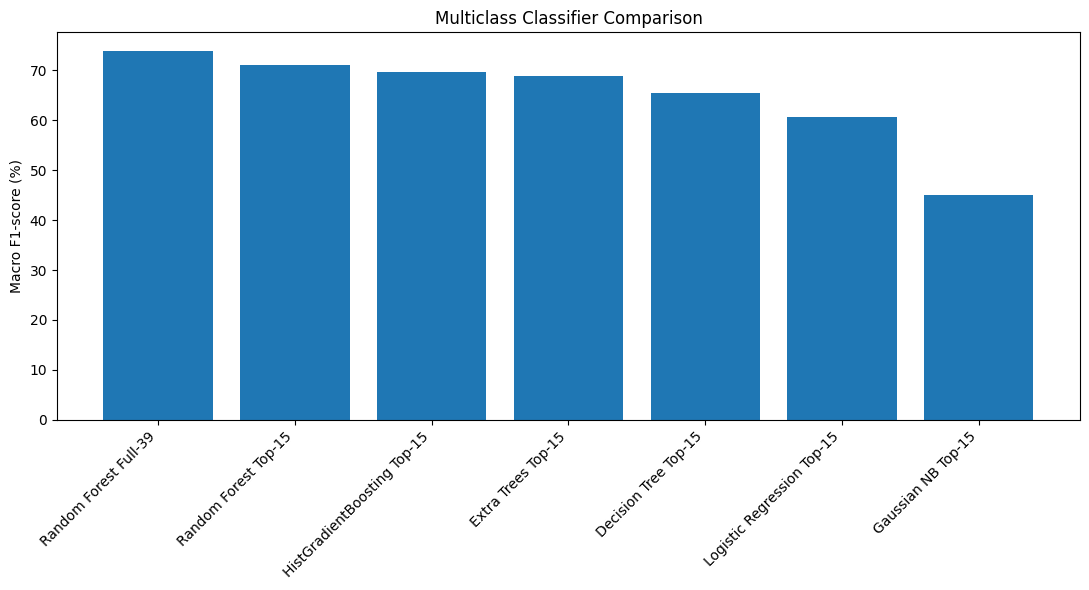

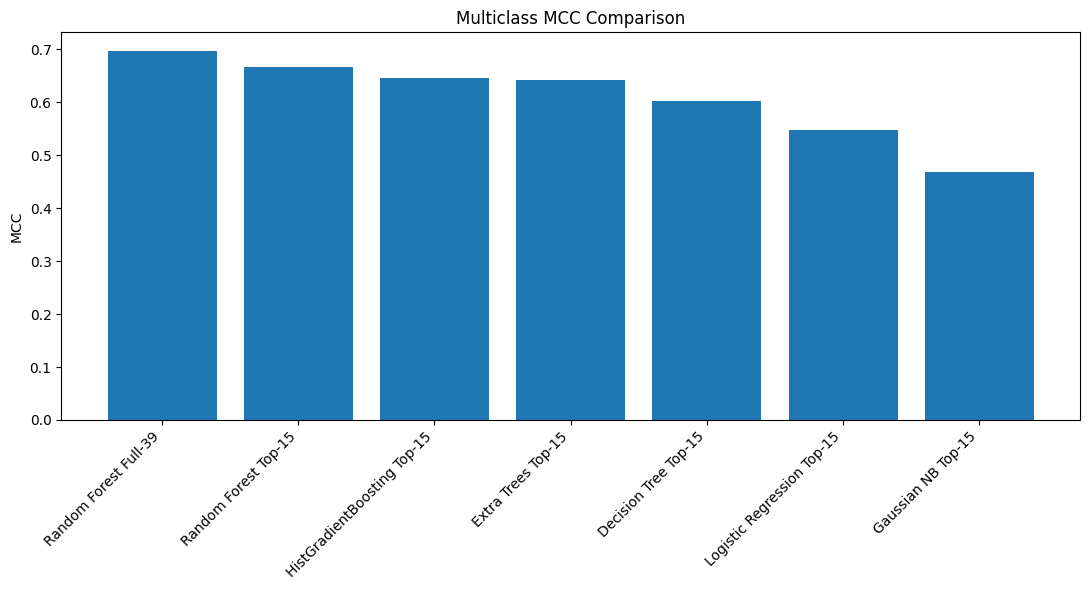

Saved figures:
outputs\multiclass\figures\multiclass_macro_f1_comparison.png
outputs\multiclass\figures\multiclass_mcc_comparison.png


In [55]:

# ============================================================
# Export paper-ready tables and plots
# ============================================================

import matplotlib.pyplot as plt

# Paper-ready multiclass table
paper_multi = multiclass_results_df.copy()

percentage_cols = [
    "Accuracy",
    "Macro_Precision",
    "Macro_Recall",
    "Macro_F1",
    "Weighted_Precision",
    "Weighted_Recall",
    "Weighted_F1"
]

for col in percentage_cols:
    paper_multi[col + " (%)"] = paper_multi[col] * 100

paper_multi_table = paper_multi[[
    "Model",
    "Features",
    "Accuracy (%)",
    "Macro_F1 (%)",
    "Weighted_F1 (%)",
    "Balanced_Accuracy",
    "MCC",
    "ROC_AUC_Macro",
    "Training_Time_sec",
    "Inference_Time_sec",
    "Model_Size_MB"
]].copy()

paper_multi_table = paper_multi_table.round({
    "Accuracy (%)": 2,
    "Macro_F1 (%)": 2,
    "Weighted_F1 (%)": 2,
    "Balanced_Accuracy": 4,
    "MCC": 4,
    "ROC_AUC_Macro": 4,
    "Training_Time_sec": 3,
    "Inference_Time_sec": 4,
    "Model_Size_MB": 2
})

paper_multi_table.to_csv(
    OUTPUT_DIR / "paper_ready_multiclass_comparison.csv",
    index=False
)

display(paper_multi_table)

latex_table = paper_multi_table.to_latex(
    index=False,
    escape=True,
    caption="Multiclass Attack Category Classification Results",
    label="tab:multiclass_classifier_comparison"
)

with open(OUTPUT_DIR / "multiclass_comparison_table.tex", "w", encoding="utf-8") as f:
    f.write(latex_table)

print(latex_table)
print("\nSaved:", OUTPUT_DIR / "multiclass_comparison_table.tex")

# Plot Macro-F1 comparison
plt.figure(figsize=(11, 6))
plt.bar(paper_multi_table["Model"], paper_multi_table["Macro_F1 (%)"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Macro F1-score (%)")
plt.title("Multiclass Classifier Comparison")
plt.tight_layout()
plt.savefig(FIG_DIR / "multiclass_macro_f1_comparison.png", dpi=300)
plt.show()

# Plot MCC comparison
plt.figure(figsize=(11, 6))
plt.bar(paper_multi_table["Model"], paper_multi_table["MCC"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("MCC")
plt.title("Multiclass MCC Comparison")
plt.tight_layout()
plt.savefig(FIG_DIR / "multiclass_mcc_comparison.png", dpi=300)
plt.show()

print("Saved figures:")
print(FIG_DIR / "multiclass_macro_f1_comparison.png")
print(FIG_DIR / "multiclass_mcc_comparison.png")


In [56]:

# ============================================================
# Detailed report for best multiclass model
# ============================================================

best_model_name = multiclass_results_df.loc[0, "Model"]
print("Best multiclass model according to Macro-F1:", best_model_name)

if best_model_name == "Random Forest Full-39":
    best_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    best_model.fit(X_train_multi_full_scaled, y_train_multi)
    best_pred = best_model.predict(X_test_multi_full_scaled)
else:
    best_model = multiclass_models_top15[best_model_name]
    best_model.fit(X_train_multi_15_scaled, y_train_multi)
    best_pred = best_model.predict(X_test_multi_15_scaled)

print("\nClassification Report for Best Multiclass Model:")
print(classification_report(
    y_test_multi,
    best_pred,
    target_names=le_multi.classes_,
    zero_division=0
))

cm_best = confusion_matrix(y_test_multi, best_pred)

cm_best_df = pd.DataFrame(
    cm_best,
    index=le_multi.classes_,
    columns=le_multi.classes_
)

display(cm_best_df)

cm_best_df.to_csv(OUTPUT_DIR / "best_multiclass_confusion_matrix.csv")
print("\nSaved:", OUTPUT_DIR / "best_multiclass_confusion_matrix.csv")


Best multiclass model according to Macro-F1: Random Forest Full-39

Classification Report for Best Multiclass Model:
                    precision    recall  f1-score   support

            BENIGN       0.67      0.66      0.66       218
              DDOS       0.80      0.68      0.74       219
               DOS       0.72      0.83      0.77       219
             MIRAI       1.00      1.00      1.00       219
             Other       0.60      0.47      0.53       219
          SPOOFING       0.90      0.87      0.88       219
VULNERABILITY_SCAN       0.53      0.68      0.60       219

          accuracy                           0.74      1532
         macro avg       0.75      0.74      0.74      1532
      weighted avg       0.75      0.74      0.74      1532



,BENIGN,DDOS,DOS,MIRAI,Other,SPOOFING,VULNERABILITY_SCAN
BENIGN,143,0,0,0,20,12,43
DDOS,0,149,70,0,0,0,0
DOS,0,37,181,1,0,0,0
MIRAI,0,0,0,219,0,0,0
Other,38,0,0,0,103,4,74
SPOOFING,12,0,0,0,5,190,12
VULNERABILITY_SCAN,22,0,0,0,44,5,148



Saved: outputs\multiclass\best_multiclass_confusion_matrix.csv


In [57]:
# ============================================================
# Improved Multiclass Sampling: Capped + Class Weighted
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef, roc_auc_score,
    classification_report, confusion_matrix
)
import time
import os
import joblib

RANDOM_STATE = 42
OUT_DIR = Path("outputs/multiclass_improved")
OUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("data/processed/final_sample_200000.csv")

# Merge very rare classes
rare_classes = ["RECON", "WEB_OR_MALWARE", "BRUTEFORCE"]
df["Attack_Category_Improved"] = df["Attack_Category"].replace({
    cls: "Other" for cls in rare_classes
})

print("Original improved class distribution:")
print(df["Attack_Category_Improved"].value_counts())

# Capped sampling: keep more data but avoid dominance
MAX_PER_CLASS = 20000

sampled_parts = []

for cls, group in df.groupby("Attack_Category_Improved"):
    n = min(len(group), MAX_PER_CLASS)
    sampled_parts.append(
        group.sample(n=n, random_state=RANDOM_STATE)
    )

multi_df = pd.concat(sampled_parts, ignore_index=True)
multi_df = multi_df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("\nImproved multiclass sample distribution:")
print(multi_df["Attack_Category_Improved"].value_counts())

multi_df.to_csv(OUT_DIR / "multiclass_capped_sample.csv", index=False)

# Prepare features
drop_cols = ["Label", "Binary_Label", "Attack_Category", "Attack_Category_Improved"]
feature_cols = [c for c in multi_df.columns if c not in drop_cols]

X_multi = multi_df[feature_cols]
y_multi_text = multi_df["Attack_Category_Improved"]

le = LabelEncoder()
y_multi = le.fit_transform(y_multi_text)

label_mapping = pd.DataFrame({
    "Encoded_Label": range(len(le.classes_)),
    "Attack_Category": le.classes_
})
print("\nLabel mapping:")
print(label_mapping)

label_mapping.to_csv(OUT_DIR / "multiclass_label_mapping.csv", index=False)

# Use existing Top-15 list
top_15_multiclass = [
    "Number", "ack_flag_number", "HTTPS", "Tot_size", "Rate",
    "Header_Length", "IAT", "AVG", "ack_count", "Variance",
    "Std", "Max", "Tot_sum", "Time_To_Live", "Min"
]

X_full = X_multi
X_top15 = X_multi[top_15_multiclass]

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_full, y_multi,
    test_size=0.2,
    stratify=y_multi,
    random_state=RANDOM_STATE
)

X_train_15, X_test_15, _, _ = train_test_split(
    X_top15, y_multi,
    test_size=0.2,
    stratify=y_multi,
    random_state=RANDOM_STATE
)

scaler_full = StandardScaler()
X_train_full_scaled = scaler_full.fit_transform(X_train_full)
X_test_full_scaled = scaler_full.transform(X_test_full)

scaler_15 = StandardScaler()
X_train_15_scaled = scaler_15.fit_transform(X_train_15)
X_test_15_scaled = scaler_15.transform(X_test_15)

print("\nTrain shape full:", X_train_full_scaled.shape)
print("Test shape full:", X_test_full_scaled.shape)
print("Train shape Top-15:", X_train_15_scaled.shape)
print("Test shape Top-15:", X_test_15_scaled.shape)

Original improved class distribution:
Attack_Category_Improved
BENIGN                100000
DDOS                   69521
DOS                    19238
MIRAI                   7693
SPOOFING                1346
VULNERABILITY_SCAN      1108
Other                   1094
Name: count, dtype: int64

Improved multiclass sample distribution:
Attack_Category_Improved
DDOS                  20000
BENIGN                20000
DOS                   19238
MIRAI                  7693
SPOOFING               1346
VULNERABILITY_SCAN     1108
Other                  1094
Name: count, dtype: int64

Label mapping:
   Encoded_Label     Attack_Category
0              0              BENIGN
1              1                DDOS
2              2                 DOS
3              3               MIRAI
4              4               Other
5              5            SPOOFING
6              6  VULNERABILITY_SCAN

Train shape full: (56383, 39)
Test shape full: (14096, 39)
Train shape Top-15: (56383, 15)
Test shape Top-

In [58]:
# ============================================================
# Improved Multiclass Model Comparison
# ============================================================

models = {
    "Random Forest Full-39": (
        RandomForestClassifier(
            n_estimators=100,
            max_depth=20,
            random_state=42,
            n_jobs=-1,
            class_weight="balanced"
        ),
        X_train_full_scaled,
        X_test_full_scaled
    ),

    "Random Forest Top-15": (
        RandomForestClassifier(
            n_estimators=100,
            max_depth=20,
            random_state=42,
            n_jobs=-1,
            class_weight="balanced"
        ),
        X_train_15_scaled,
        X_test_15_scaled
    ),

    "Extra Trees Top-15": (
        ExtraTreesClassifier(
            n_estimators=100,
            max_depth=20,
            random_state=42,
            n_jobs=-1,
            class_weight="balanced"
        ),
        X_train_15_scaled,
        X_test_15_scaled
    ),

    "Decision Tree Top-15": (
        DecisionTreeClassifier(
            max_depth=20,
            random_state=42,
            class_weight="balanced"
        ),
        X_train_15_scaled,
        X_test_15_scaled
    ),

    "Logistic Regression Top-15": (
        LogisticRegression(
            max_iter=1000,
            solver="lbfgs",
            class_weight="balanced",
            random_state=42
        ),
        X_train_15_scaled,
        X_test_15_scaled
    ),

    "Gaussian NB Top-15": (
        GaussianNB(),
        X_train_15_scaled,
        X_test_15_scaled
    ),

    "HistGradientBoosting Top-15": (
        HistGradientBoostingClassifier(
            max_iter=100,
            learning_rate=0.1,
            max_leaf_nodes=31,
            random_state=42
        ),
        X_train_15_scaled,
        X_test_15_scaled
    )
}

def evaluate_multiclass_model(name, model, Xtr, Xte, ytr, yte):
    start_train = time.time()
    model.fit(Xtr, ytr)
    train_time = time.time() - start_train

    start_pred = time.time()
    y_pred = model.predict(Xte)
    inference_time = time.time() - start_pred

    roc_auc_macro = np.nan
    try:
        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(Xte)
            roc_auc_macro = roc_auc_score(
                yte, y_prob,
                multi_class="ovr",
                average="macro"
            )
    except Exception:
        pass

    return {
        "Model": name,
        "Features": Xtr.shape[1],
        "Accuracy": accuracy_score(yte, y_pred),
        "Macro_Precision": precision_score(yte, y_pred, average="macro", zero_division=0),
        "Macro_Recall": recall_score(yte, y_pred, average="macro", zero_division=0),
        "Macro_F1": f1_score(yte, y_pred, average="macro", zero_division=0),
        "Weighted_F1": f1_score(yte, y_pred, average="weighted", zero_division=0),
        "Balanced_Accuracy": balanced_accuracy_score(yte, y_pred),
        "MCC": matthews_corrcoef(yte, y_pred),
        "ROC_AUC_Macro": roc_auc_macro,
        "Training_Time_sec": train_time,
        "Inference_Time_sec": inference_time
    }, model, y_pred

results = []
trained_models = {}
predictions = {}

for name, (model, Xtr, Xte) in models.items():
    print("\nTraining:", name)
    res, trained, pred = evaluate_multiclass_model(
        name, model, Xtr, Xte, y_train, y_test
    )
    results.append(res)
    trained_models[name] = trained
    predictions[name] = pred

    print(
        f"Accuracy={res['Accuracy']:.4f}, "
        f"Macro-F1={res['Macro_F1']:.4f}, "
        f"MCC={res['MCC']:.4f}, "
        f"ROC-AUC={res['ROC_AUC_Macro']:.4f}"
    )

improved_results_df = pd.DataFrame(results).sort_values(
    by="Macro_F1",
    ascending=False
)

improved_results_df.to_csv(
    OUT_DIR / "improved_multiclass_classifier_comparison.csv",
    index=False
)

display(improved_results_df)


Training: Random Forest Full-39
Accuracy=0.8485, Macro-F1=0.7356, MCC=0.8024, ROC-AUC=0.9720

Training: Random Forest Top-15
Accuracy=0.8138, Macro-F1=0.7061, MCC=0.7580, ROC-AUC=0.9628

Training: Extra Trees Top-15
Accuracy=0.7980, Macro-F1=0.6952, MCC=0.7423, ROC-AUC=0.9604

Training: Decision Tree Top-15
Accuracy=0.7661, Macro-F1=0.6552, MCC=0.7001, ROC-AUC=0.8708

Training: Logistic Regression Top-15
Accuracy=0.6518, Macro-F1=0.5189, MCC=0.5648, ROC-AUC=0.9353

Training: Gaussian NB Top-15
Accuracy=0.5323, Macro-F1=0.4029, MCC=0.4656, ROC-AUC=0.9237

Training: HistGradientBoosting Top-15
Accuracy=0.8148, Macro-F1=0.7018, MCC=0.7582, ROC-AUC=0.9662


,Model,Features,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Balanced_Accuracy,MCC,ROC_AUC_Macro,Training_Time_sec,Inference_Time_sec
0,Random Forest Full-39,39,0.848539,0.816408,0.698818,0.735593,0.842548,0.698818,0.802447,0.971973,4.394891,0.193356
1,Random Forest Top-15,15,0.813777,0.784464,0.672330,0.706053,0.806004,0.672330,0.757991,0.962840,4.289083,0.159629
6,HistGradientBoosting Top-15,15,0.814841,0.769529,0.673827,0.701800,0.807217,0.673827,0.758232,0.966153,9.523152,0.418716
2,Extra Trees Top-15,15,0.797957,0.711738,0.702239,0.695165,0.795625,0.702239,0.742272,0.960430,2.430397,0.159790
3,Decision Tree Top-15,15,0.766104,0.649251,0.694038,0.655204,0.773080,0.694038,0.700081,0.870790,1.400128,0.008515
4,Logistic Regression Top-15,15,0.651816,0.524217,0.611782,0.518945,0.678522,0.611782,0.564807,0.935340,9.281000,0.010012
5,Gaussian NB Top-15,15,0.532279,0.517459,0.562286,0.402941,0.517530,0.562286,0.465640,0.923673,0.047595,0.034003
